# Predicting Titled Tuesday outcomes before play

Executed data audits, training results, and evaluation plots. See [README.md](README.md) for the experiment purpose, one-command pipeline run, feature definitions, decisions, and submission notes.

In [1]:
import sys
sys.dont_write_bytecode = True
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import sklearn
from IPython.display import display
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

from chess_pipeline.api import ChessComClient
from chess_pipeline.config import CLASS_NAMES, CLASS_IDS, FEATURES, PipelineConfig
from chess_pipeline.pipeline import run_data_pipeline
from chess_pipeline.modeling import train_models, training_class_prior, get_gain_importance
from chess_pipeline.evaluation import evaluate_models

config = PipelineConfig()
client = ChessComClient()
print({'python': platform.python_version(), 'pandas': pd.__version__,
       'numpy': np.__version__, 'lightgbm': lgb.__version__, 'sklearn': sklearn.__version__,
       'seed': config.seed, 'cache': str(client.cache_dir)})

{'python': '3.11.9', 'pandas': '2.3.3', 'numpy': '2.3.2', 'lightgbm': '4.7.0', 'sklearn': '1.7.2', 'seed': 42, 'cache': 'C:\\Users\\vince\\AppData\\Local\\Temp\\chess-take-home-api-v1'}


## Data and pre-game features

Seven features, using strictly prior-game ratings and pre-tournament histories.

In [2]:
data = run_data_pipeline(config, client)
raw = data.raw
print(raw.attrs['audit'])
print(f'{len(raw):,} unique games; {raw.event_id.nunique()} tournaments')
display(raw.groupby('event_id').agg(
    games=('game_id', 'size'), players_white=('white', 'nunique'),
    rounds=('round', 'nunique'), first_game=('start_time', 'min')))
display(raw.groupby(['event_id', 'time_control']).size().rename('games').to_frame())

Collected titled-tuesday-blitz-january-06-2026-6140433


Collected titled-tuesday-blitz-january-13-2026-6151065


Collected titled-tuesday-blitz-january-20-2026-6160609


Collected titled-tuesday-blitz-january-27-2026-6170439


Collected titled-tuesday-blitz-february-03-2026-6190821


Collected titled-tuesday-blitz-february-10-2026-6221327


... (3 outputs left out)

Collected titled-tuesday-blitz-march-10-2026-6277141


{'source': 'Chess.com Published Data API tournament round/group games', 'discovery_seeds': ['hikaru', 'magnuscarlsen'], 'start': '2026-01-01', 'end': '2026-03-10', 'events': 10, 'rows_before_dedup': 19543, 'duplicates_removed': 0, 'skipped_games': 0, 'cache_dir': 'C:\\Users\\vince\\AppData\\Local\\Temp\\chess-take-home-api-v1', 'missing_prior_rating_games': 1030}
19,543 unique games; 10 tournaments


,games,players_white,rounds,first_game
event_id,,,,
titled-tuesday-blitz-february-03-2026-6190821,1982,429,11,1770134400
titled-tuesday-blitz-february-10-2026-6221327,2025,444,11,1770739200
titled-tuesday-blitz-february-17-2026-6221393,1928,426,11,1771344001
titled-tuesday-blitz-february-24-2026-6256793,1842,419,11,1771948800
titled-tuesday-blitz-january-06-2026-6140433,1951,436,11,1767715201
titled-tuesday-blitz-january-13-2026-6151065,1950,429,11,1768320000
titled-tuesday-blitz-january-20-2026-6160609,1846,409,11,1768924801
titled-tuesday-blitz-january-27-2026-6170439,1987,434,11,1769529600
titled-tuesday-blitz-march-03-2026-6262447,1994,430,11,1772553601


,,games
event_id,time_control,
titled-tuesday-blitz-february-03-2026-6190821,300,1982
titled-tuesday-blitz-february-10-2026-6221327,300,2025
titled-tuesday-blitz-february-17-2026-6221393,300,1928
titled-tuesday-blitz-february-24-2026-6256793,300,1842
titled-tuesday-blitz-january-06-2026-6140433,300,1951
titled-tuesday-blitz-january-13-2026-6151065,300,1950
titled-tuesday-blitz-january-20-2026-6160609,300,1846
titled-tuesday-blitz-january-27-2026-6170439,300,1987
titled-tuesday-blitz-march-03-2026-6262447,300,1994


In [3]:
coverage = data.coverage
print(f'Target games excluded for missing prior ratings: {coverage.missing_prior_rating.sum():,} / {len(coverage):,}')
display(coverage.groupby('event_id').agg(
    collected=('game_id', 'size'), excluded_missing_prior=('missing_prior_rating', 'sum')))
table = data.table
parts = data.parts
train, validation, test = [parts[name] for name in ('train', 'validation', 'test')]

audit = table.groupby('split', sort=False).agg(
    games=('game_id', 'size'), events=('event_id', 'nunique'),
    first_event=('event_start', 'min'), last_event=('event_start', 'max'))
audit = audit.assign(
    first_event=pd.to_datetime(audit.first_event, unit='s', utc=True),
    last_event=pd.to_datetime(audit.last_event, unit='s', utc=True))
display(audit)
display(pd.crosstab(table['split'], table['outcome']).reindex(
    index=['train', 'validation', 'test'], columns=CLASS_NAMES, fill_value=0))
display(table.groupby('split')[[f'{c}_history_count' for c in ('white', 'black')]].describe())
print('Zero-history fractions:', {c: float(table[f'{c}_history_count'].eq(0).mean())
                                  for c in ('white', 'black')})
print('Feature whitelist:', FEATURES)
print('Frozen validation/test dates:', sorted(validation.event_id.unique()), sorted(test.event_id.unique()))

Target games excluded for missing prior ratings: 417 / 11,809


,collected,excluded_missing_prior
event_id,,
titled-tuesday-blitz-february-03-2026-6190821,1982,88
titled-tuesday-blitz-february-10-2026-6221327,2025,67
titled-tuesday-blitz-february-17-2026-6221393,1928,84
titled-tuesday-blitz-february-24-2026-6256793,1842,60
titled-tuesday-blitz-march-03-2026-6262447,1994,62
titled-tuesday-blitz-march-10-2026-6277141,2038,56


,games,events,first_event,last_event
split,,,,
train,7478,4,2026-02-03 16:00:00+00:00,2026-02-24 16:00:00+00:00
validation,1932,1,2026-03-03 16:00:00+00:00,2026-03-03 16:00:00+00:00
test,1982,1,2026-03-10 16:00:00+00:00,2026-03-10 16:00:00+00:00


outcome,black_win,draw,white_win
split,,,
train,3230,607,3641
validation,839,167,926
test,906,149,927


white_history_count                                               \
                         count       mean        std  min   25%   50%   75%   
split                                                                         
test                    1982.0  37.951564  27.261196  0.0  11.0  34.0  61.0   
train                   7478.0  27.541722  20.343212  0.0  11.0  26.0  43.0   
validation              1932.0  37.008282  27.797763  0.0  11.0  33.0  63.0   

                 black_history_count                                         \
             max               count       mean        std  min   25%   50%   
split                                                                         
test        88.0              1982.0  37.682644  27.273822  0.0  11.0  33.0   
train       77.0              7478.0  27.579299  20.314922  0.0  11.0  26.0   
validation  88.0              1932.0  37.042961  27.990709  0.0  11.0  33.0   

                        
             75%   max  
split                   
test        61.0  88.0  
train       44.0  77.0  
validation  64.0  88.0

Zero-history fractions: {'white': 0.14483848314606743, 'black': 0.14360955056179775}
Feature whitelist: ('rating_diff', 'mean_rating', 'round', 'white_form', 'white_draw_rate', 'black_form', 'black_draw_rate')
Frozen validation/test dates: ['titled-tuesday-blitz-march-03-2026-6262447'] ['titled-tuesday-blitz-march-10-2026-6277141']


## Training and feature importance

Both LightGBM variants use the same settings and validation-only early stopping. Gain importance describes training split contributions.

In [4]:
models = train_models(train, validation, seed=config.seed)
prior = training_class_prior(train)
print('Training class prior:', dict(zip(CLASS_NAMES, prior)))
print('Selected tree iterations:', {name: model.best_iteration_
                                     for name, (model, _) in models.items()})

Training class prior: {'black_win': np.float64(0.43193367210484085), 'draw': np.float64(0.08117143621289115), 'white_win': np.float64(0.48689489168226796)}
Selected tree iterations: {'rating_only': 45, 'historical_features': 45}


,feature,gain
0,rating_diff,26698.332201
1,mean_rating,1092.830978
2,round,293.739780
6,black_draw_rate,216.751619
3,white_form,193.540061
4,white_draw_rate,94.886370
5,black_form,76.130340


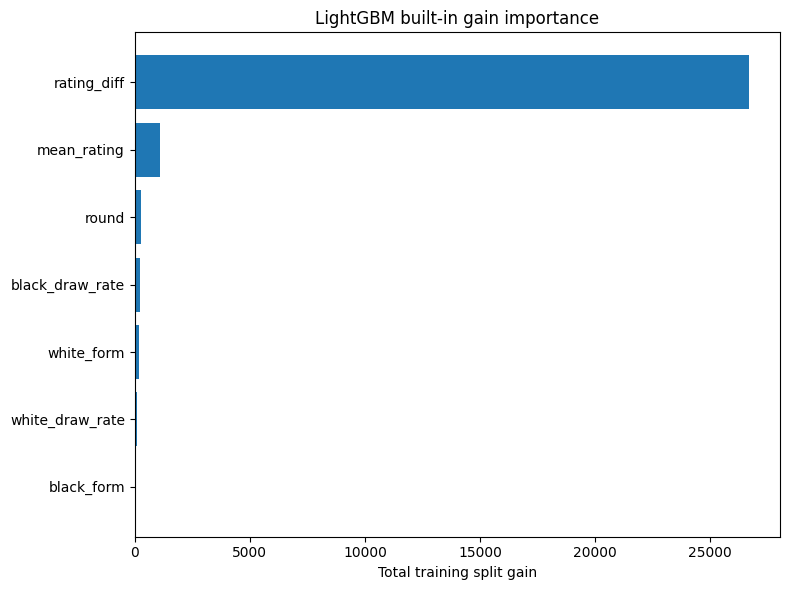

In [5]:
importance_table = get_gain_importance(models['historical_features'][0])
display(importance_table)
plot = importance_table.sort_values('gain')
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot.feature, plot.gain)
ax.set(xlabel='Total training split gain', title='LightGBM built-in gain importance')
plt.tight_layout()
plt.show()

## Evaluation

All comparisons use the same eligible games. The deterministic rule receives accuracy only; the learned models also receive probability metrics. This is a reused exploratory holdout.

log_loss  accuracy  roc_auc_ovo_macro  \
split      model                                                        
validation class_prior           0.92658   0.47930            0.50000   
           rating_only           0.81830   0.66046            0.65499   
           historical_features   0.81726   0.66046            0.65599   
test       class_prior           0.90914   0.46771            0.50000   
           rating_only           0.76619   0.69627            0.68496   
           historical_features   0.76636   0.69677            0.68337   

                                brier_multiclass  
split      model                                  
validation class_prior                   0.57431  
           rating_only                   0.48148  
           historical_features           0.48023  
test       class_prior                   0.56768  
           rating_only                   0.44502  
           historical_features           0.44511

accuracy
split      model                        
validation class_prior           0.47930
           rating_only           0.66046
           historical_features   0.66046
           higher_rating_rule    0.65942
test       class_prior           0.46771
           rating_only           0.69627
           historical_features   0.69677
           higher_rating_rule    0.69576

              precision    recall  f1-score   support

   black_win      0.696     0.755     0.724       906
        draw      0.000     0.000     0.000       149
   white_win      0.698     0.752     0.724       927

    accuracy                          0.697      1982
   macro avg      0.465     0.502     0.483      1982
weighted avg      0.644     0.697     0.670      1982



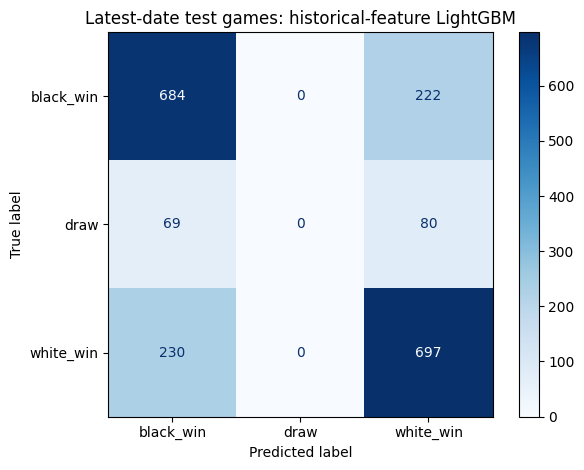

,event,model,games,log_loss,accuracy,roc_auc_ovo_macro,brier_multiclass
0,titled-tuesday-blitz-march-10-2026-6277141,rating_only,1982,0.76619,0.69627,0.68496,0.44502
1,titled-tuesday-blitz-march-10-2026-6277141,historical_features,1982,0.76636,0.69677,0.68337,0.44511


Test log-loss improvement over ratings (positive = better): -0.00017
Test covers 1 tournament(s) on 1 date(s).
Prior-game ratings replace leaked post-game ratings; earlier metrics are superseded.
This is still a reused exploratory holdout, not independent final confirmation.


In [6]:
evaluation = evaluate_models(models, prior, parts)
results = evaluation.metrics
accuracy_comparison = evaluation.accuracy_comparison
predictions = evaluation.predictions
display(results.round(5))
display(accuracy_comparison.round(5))

test_probabilities = predictions['test']['historical_features']
print(classification_report(test['y'], test_probabilities.argmax(axis=1),
                            labels=CLASS_IDS, target_names=CLASS_NAMES,
                            zero_division=0, digits=3))
ConfusionMatrixDisplay.from_predictions(
    test['y'], test_probabilities.argmax(axis=1), labels=CLASS_IDS,
    display_labels=CLASS_NAMES, cmap='Blues')
plt.title('Latest-date test games: historical-feature LightGBM')
plt.tight_layout()
plt.show()
display(evaluation.per_event.round(5))

base_loss = results.loc[('test', 'rating_only'), 'log_loss']
full_loss = results.loc[('test', 'historical_features'), 'log_loss']
print(f'Test log-loss improvement over ratings (positive = better): {base_loss-full_loss:+.5f}')
print(f'Test covers {test.event_id.nunique()} tournament(s) on '
      f'{pd.to_datetime(test.event_start, unit="s", utc=True).dt.date.nunique()} date(s).')
print('Prior-game ratings replace leaked post-game ratings; earlier metrics are superseded.')
print('This is still a reused exploratory holdout, not independent final confirmation.')

## Interpretation

The additional features do not demonstrate meaningful improvement over ratings alone, and draw recall is zero under argmax classification. See [results and limitations](README.md#results-and-model-quality).